In [2]:
import polars as pl
import utils as ut
import geopandas as gpd
import pandas as pd
foursquare = pl.read_parquet(
    "data/input_files/uk_foursquare_datefields_admin_categories.parquet"
)


foursquare = foursquare.filter(
    (foursquare["level1_category_name"] == "Retail")
    | (foursquare["level1_category_name"] == "Dining and Drinking")
    | (foursquare["level1_category_name"] == "Arts and Entertainment")
    | (foursquare["level1_category_name"] == "Sports and Recreation")
    
    #level 1 Buisness and Professional Services
    | (foursquare["level2_category_name"] == "Health and Beauty Service")  #buissness
    | (foursquare["level2_category_name"] == "Automotive Service")  #buissness
    # | (foursquare["level3_category_name"] == "ATM") #buisness, finanaical service
    | (foursquare["level4_category_name"] == "Bank") #buisness, finanaical service
    | (foursquare["level3_category_name"] == "Credit Union") #buisness, finanaical service
    | (foursquare["level3_category_name"] == "Real Estate Agency") #buisness,real estate serice
    | (foursquare["level3_category_name"] == "Law Office") 
    | (foursquare["level3_category_name"] == "Loans Agency") #buisness, finanaical service
    # | (foursquare["level3_category_name"] == "Insurance Agency") #buisness, finanaical service
    | (foursquare["level2_category_name"] == "Computer Repair Service") #buisness
    | (foursquare["level2_category_name"] == "Pet Service") #buisness
    | (foursquare["level2_category_name"] == "Photography Service") #buisness
    | (foursquare["level2_category_name"] == "Locksmith") #buisness
    | (foursquare["level2_category_name"] == "Funeral Home") #buisness
    | (foursquare["level3_category_name"] == "Coworking Space") #buisness, offce
    | (foursquare["level2_category_name"] == "Laundry Service") #buisness
    | (foursquare["level2_category_name"] == "Laundromat") #buisness
    #Level 1 Travel and Transportation
    | (foursquare["level2_category_name"] == "Fuel Station") #transsport
    | (foursquare["level2_category_name"] == "Travel Agency") #transsport
    | (foursquare["level2_category_name"] == "Tourist Information and Service") #transsport (covers tourist info shops and some travel agencies)
    #Level 1 Health and Medicine
    | (foursquare["level3_category_name"] == "Doctors Office") #most gps
    | (foursquare["level2_category_name"] == "Dentist") #dentists
    | (foursquare["level2_category_name"] == "Veterinarian") #vets
    | (foursquare["level2_category_name"] == "Physical Therapy Clinic") #physio
    # Level 1 Community and Government
    | (foursquare["level3_category_name"] == "Post Office") #community
    | (foursquare["level2_category_name"] == "Library") #community
    | (foursquare["level2_category_name"] == "Community Center") #community
    | (foursquare["level2_category_name"] == "Social Club") #community
)



In [71]:
print(len(foursquare))

2222411


In [3]:
#load alexs filt
cats = pl.read_csv("data/POI_files/alex_filter.csv")
#set the nulls in the remove column to 0
cats = cats.with_columns(
    pl.col("Remove").fill_null(0).cast(pl.Int64)
)
cats = cats.filter(~(cats["Remove"] == 1))
# cats = cats.filter(cats["Remove"] != 1)


def filter_matching_categories(data_df, reference_df):
    """
    Filter rows in data_df where the category hierarchy matches one from reference_df,
    considering null values as valid matches when they appear in both DataFrames.
    """
    category_cols = [
        'level1_category_name',
        'level2_category_name',
        'level3_category_name',
        'level4_category_name'
    ]
    
    # Create an expression that matches categories including nulls
    conditions = []
    
    for col in category_cols:
        # A category matches if either:
        # 1. Both values are null, or
        # 2. The value exists in the reference DataFrame for this column
        condition = (
            (pl.col(col).is_null() & pl.lit(reference_df[col].null_count() > 0)) |
            pl.col(col).is_in(reference_df.select(col).filter(pl.col(col).is_not_null()).unique())
        )
        conditions.append(condition)
    
    # Combine all conditions with AND
    final_condition = conditions[0]
    for cond in conditions[1:]:
        final_condition = final_condition & cond
    
    # Apply the filter
    result = data_df.filter(final_condition)
    
    return result
foursquare = filter_matching_categories(foursquare, cats)


In [4]:
foursquare

fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,email,facebook_id,instagram,twitter,fsq_category_ids,fsq_category_labels,dt_x,geometry,h3_01,h3_02,h3_03,h3_04,h3_05,h3_06,h3_07,h3_08,h3_09,easting,northing,LAD22CD,LAD22NM,OA21CD,LSOA21CD,LSOA21NM,MSOA21CD,MSOA21NM,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm,num_categories,category_id,category_level,category_name,category_label,level1_category_id,level1_category_name,level2_category_id,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,list[str],str,binary,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,i32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,datetime[μs]
"""4c84e10830789c74a24469e3""","""Bellcraig community centre""",55.901058,-4.292746,"""10 Gorstan St""","""Glasgow""","""Uk""","""G23 5QA""","""Scotland""",null,null,"""GB""","""2010-09-06""","""2024-10-08""",null,"""0141 945 2710""","""http://www.glasgowlife.co.uk""",null,1.5168e14,null,null,"""52e81612bcbc57f1066b7a34""","[""Community and Government > Community Center""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\x15_\x0b\x94mW\x0fAy\xd5\x0d\xd4\xc9q$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909af7ffffff""","""871909af1ffffff""","""881909ae25fffff""","""891909ae24bffff""",256749.697287,669924.914168,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010349""","""Summerston North - 04""",null,null,null,null,null,null,null,null,1,"""52e81612bcbc57f1066b7a34""",2,"""Community Center""","""Community and Government > Com…","""63be6904847c3692a84b9b9a""","""Community and Government""","""52e81612bcbc57f1066b7a34""","""Community Center""",null,null,null,null,null,null,null,null,2024-11-19 00:00:00
"""4f00b62b0e01089c566a7769""","""DJ's""",55.843726,-4.262244,null,null,null,null,null,null,null,"""GB""","""2012-01-01""","""2023-06-15""","""2018-10-26""",null,null,null,null,null,null,"""4bf58dd8d48988d116941735""","[""Dining and Drinking > Bar""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xd3`\xfc7~\x8c\x0fA\x91\xca\x9b\x05v?$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909ac7ffffff""","""871909ac1ffffff""","""881909ac1bfffff""","""891909ac1bbffff""",258447.777337,663483.010954,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010033""","""Laurieston and Tradeston - 03""",null,null,null,null,null,null,null,null,1,"""4bf58dd8d48988d116941735""",2,"""Bar""","""Dining and Drinking > Bar""","""63be6904847c3692a84b9bb5""","""Dining and Drinking""","""4bf58dd8d48988d116941735""","""Bar""",null,null,null,null,null,null,null,null,2024-11-19 00:00:00
"""4b8e9615f964a5205a2a33e3""","""The Forge Shopping Centre""",55.853484,-4.200165,"""1221 Gallowgate""","""Glasgow""","""Glasgow City""","""G31 4EB""","""Scotland""",null,null,"""GB""","""2010-03-03""","""2024-02-07""",null,"""0141 556 6661""","""http://forgeshopping.com""","""vince.lochrie@forgeshoppingcen…",3.8633e14,null,"""forgeshopping""","""4bf58dd8d48988d1fd941735""","[""Retail > Shopping Mall""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xb2\xc6\x08\x94\x82\x03\x10A\x9e|\x83\xc2\xf6F$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909aefffffff""","""871909ae8ffffff""","""881909ae8dfffff""","""891909ae8c7ffff""",262368.644565,664443.379909,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010052""","""Parkhead West and Barrowfield …",null,null,null,null,nul

In [5]:

#remove any with a date closed
foursquare = foursquare.filter(foursquare["date_closed"].is_null())
#remove any with same name and lat lng (some have multiple categories)
foursquare = foursquare.unique(subset=["name","lat","lng"])

In [6]:
foursquare

fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,email,facebook_id,instagram,twitter,fsq_category_ids,fsq_category_labels,dt_x,geometry,h3_01,h3_02,h3_03,h3_04,h3_05,h3_06,h3_07,h3_08,h3_09,easting,northing,LAD22CD,LAD22NM,OA21CD,LSOA21CD,LSOA21NM,MSOA21CD,MSOA21NM,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm,num_categories,category_id,category_level,category_name,category_label,level1_category_id,level1_category_name,level2_category_id,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,list[str],str,binary,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,i32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,datetime[μs]
"""4c84e10830789c74a24469e3""","""Bellcraig community centre""",55.901058,-4.292746,"""10 Gorstan St""","""Glasgow""","""Uk""","""G23 5QA""","""Scotland""",null,null,"""GB""","""2010-09-06""","""2024-10-08""",null,"""0141 945 2710""","""http://www.glasgowlife.co.uk""",null,1.5168e14,null,null,"""52e81612bcbc57f1066b7a34""","[""Community and Government > Community Center""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\x15_\x0b\x94mW\x0fAy\xd5\x0d\xd4\xc9q$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909af7ffffff""","""871909af1ffffff""","""881909ae25fffff""","""891909ae24bffff""",256749.697287,669924.914168,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010349""","""Summerston North - 04""",null,null,null,null,null,null,null,null,1,"""52e81612bcbc57f1066b7a34""",2,"""Community Center""","""Community and Government > Com…","""63be6904847c3692a84b9b9a""","""Community and Government""","""52e81612bcbc57f1066b7a34""","""Community Center""",null,null,null,null,null,null,null,null,2024-11-19 00:00:00
"""4b8e9615f964a5205a2a33e3""","""The Forge Shopping Centre""",55.853484,-4.200165,"""1221 Gallowgate""","""Glasgow""","""Glasgow City""","""G31 4EB""","""Scotland""",null,null,"""GB""","""2010-03-03""","""2024-02-07""",null,"""0141 556 6661""","""http://forgeshopping.com""","""vince.lochrie@forgeshoppingcen…",3.8633e14,null,"""forgeshopping""","""4bf58dd8d48988d1fd941735""","[""Retail > Shopping Mall""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xb2\xc6\x08\x94\x82\x03\x10A\x9e|\x83\xc2\xf6F$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909aefffffff""","""871909ae8ffffff""","""881909ae8dfffff""","""891909ae8c7ffff""",262368.644565,664443.379909,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010052""","""Parkhead West and Barrowfield …",null,null,null,null,null,null,null,null,1,"""4bf58dd8d48988d1fd941735""",2,"""Shopping Mall""","""Retail > Shopping Mall""","""4d4b7105d754a06378d81259""","""Retail""","""4bf58dd8d48988d1fd941735""","""Shopping Mall""",null,null,null,null,null,null,null,null,2024-11-19 00:00:00
"""5ed0dbee121646647fb9a511""","""Desa Ink""",55.882145,-4.254049,"""158 Saracen St""","""Glasgow""","""Lanarkshire""","""G22 5AS""","""Scotland""","""Glasgow""",null,"""GB""","""2014-06-12""","""2024-06-24""",null,"""0141 336 7299""",null,null,null,null,null,"""4bf58dd8d48988d1de931735""","[""Business and Professional Services > Health and Beauty Service > Tattoo Parlor""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xf4\xf9\xd0\xc2\xe0\xa0\x0fA\x87w2\xf3\xb9`$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909ae7ffffff""","""871909ae3ffffff""","""881909ae31fffff""","""891909ae30bffff""",259100.095125,667740.974994

In [11]:
foursquare

fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,email,facebook_id,instagram,twitter,fsq_category_ids,fsq_category_labels,dt_x,geometry,h3_01,h3_02,h3_03,h3_04,h3_05,h3_06,h3_07,h3_08,h3_09,easting,northing,LAD22CD,LAD22NM,OA21CD,LSOA21CD,LSOA21NM,MSOA21CD,MSOA21NM,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm,num_categories,category_id,category_level,category_name,category_label,level1_category_id,level1_category_name,level2_category_id,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,list[str],str,binary,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,i32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,datetime[μs]
"""d88cd40c14ed4fc3b4a4999b""","""Porch 2005 Limited""",51.619365,-2.95885,"""Ponthir Rd""","""Caerleon""","""Gwent""","""NP18 3XL""","""Wales""","""Newport""",null,"""GB""","""2021-12-15""","""2024-10-09""",null,"""01432 374700""",null,null,null,null,null,"""4eb1c1623b7b52c0e1adc2ec""","[""Retail > Automotive Retail > Car Dealership""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xe2\xc4\xbd)D^\x14A\xd0\xd4\x9e\xa7\xb7c\x07A""","""81197ffffffffff""","""82195ffffffffff""","""831958fffffffff""","""8419587ffffffff""","""85195847fffffff""","""86195844fffffff""","""871958449ffffff""","""88195844d7fffff""","""89195844d6fffff""",333713.040763,191606.956846,"""W06000022""","""Newport""","""W00008447""","""W01001628""","""Newport 001F""","""W02000347""","""Newport 001""",null,null,null,null,null,null,null,null,null,null,1,"""4eb1c1623b7b52c0e1adc2ec""",3,"""Car Dealership""","""Retail > Automotive Retail > C…","""4d4b7105d754a06378d81259""","""Retail""","""63be6904847c3692a84b9be3""","""Automotive Retail""","""4eb1c1623b7b52c0e1adc2ec""","""Car Dealership""",null,null,null,null,null,null,2024-11-19 00:00:00
"""a2406c1ad7324dde101744eb""","""Eurocell Building Plastics""",53.612567,-2.145683,"""Magnum Trade Park Unit 4""","""Rochdale""","""Greater Manchester""","""OL16 5NP""","""England""","""Rochdale""",null,"""GB""","""2015-11-12""","""2024-10-09""",null,"""0333 234 1097""","""http://www.eurocell.co.uk""",null,null,null,null,"""4bf58dd8d48988d112951735""","[""Retail > Hardware Store""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\x85V\x01D\xed\xd4\x17A,\xa3\x20Y\x923\x19A""","""81197ffffffffff""","""821957fffffffff""","""831942fffffffff""","""8419425ffffffff""","""8519424ffffffff""","""8619424f7ffffff""","""8719424f5ffffff""","""8819424f59fffff""","""8919424f513ffff""",390459.316411,412900.587039,"""E08000005""","""Rochdale""","""E00028161""","""E01005564""","""Rochdale 015E""","""E02001146""","""Rochdale 015""",null,null,null,null,null,null,null,null,null,null,1,"""4bf58dd8d48988d112951735""",2,"""Hardware Store""","""Retail > Hardware Store""","""4d4b7105d754a06378d81259""","""Retail""","""4bf58dd8d48988d112951735""","""Hardware Store""",null,null,null,null,null,null,null,null,2024-11-19 00:00:00
"""5f719959df94065688d5efcb""","""Angie’s Snack Shack""",51.646469,-4.000026,null,"""Swansea""","""Wales""","""SA5 4NE""","""Wales""",null,null,"""GB""","""2020-09-28""","""2024-05-22""",null,"""07938 897708""",null,null,null,null,null,"""4bf58dd8d48988d16d941735""","[""Dining and Drinking > Cafe, Coffee, and Tea House > Café"", ""Dining and Drinking > Breakfast Spot""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xf7\xab\x8a\xe1\xa9\xf2\x0fA\x8c\x1d2\xe1\x84\xef\x07A""","""81197ffffffffff""","""82195ffffffffff""","""83195afffffffff""","""84195a1ffffffff""","""85195a17fffffff""","""86195a177ffffff""","""87195a173ffffff""","""88195a1735fffff""","""89195a17343ffff""",261717.235128,1960

In [13]:
foursquare1

fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,email,facebook_id,instagram,twitter,fsq_category_ids,fsq_category_labels,dt_x,geometry,h3_01,h3_02,h3_03,h3_04,h3_05,h3_06,h3_07,h3_08,h3_09,easting,northing,LAD22CD,LAD22NM,OA21CD,LSOA21CD,LSOA21NM,MSOA21CD,MSOA21NM,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm,num_categories,category_id,category_level,category_name,category_label,level1_category_id,level1_category_name,level2_category_id,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,list[str],str,binary,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,i32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,datetime[μs]
"""4c84e10830789c74a24469e3""","""Bellcraig community centre""",55.901058,-4.292746,"""10 Gorstan St""","""Glasgow""","""Uk""","""G23 5QA""","""Scotland""",null,null,"""GB""","""2010-09-06""","""2024-10-08""",null,"""0141 945 2710""","""http://www.glasgowlife.co.uk""",null,1.5168e14,null,null,"""52e81612bcbc57f1066b7a34""","[""Community and Government > Community Center""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\x15_\x0b\x94mW\x0fAy\xd5\x0d\xd4\xc9q$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909af7ffffff""","""871909af1ffffff""","""881909ae25fffff""","""891909ae24bffff""",256749.697287,669924.914168,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010349""","""Summerston North - 04""",null,null,null,null,null,null,null,null,1,"""52e81612bcbc57f1066b7a34""",2,"""Community Center""","""Community and Government > Com…","""63be6904847c3692a84b9b9a""","""Community and Government""","""52e81612bcbc57f1066b7a34""","""Community Center""",null,null,null,null,null,null,null,null,2024-11-19 00:00:00


In [111]:
filtered_foursquare.write_csv("data/POI_files/foursquare_filtered.csv")

In [115]:
len(filtered_foursquare)

1901106

In [114]:
remaining_cats = filtered_foursquare.select(["level1_category_name","level2_category_name","level3_category_name","level4_category_name"])
remaining_cats = remaining_cats.unique()

#sort by all levels
remaining_cats = remaining_cats.sort([
    "level1_category_name",
    "level2_category_name",
    "level3_category_name",
    "level4_category_name"
])
remaining_cats.write_csv("data/POI_files/foursquare_remaining_categories.csv")

In [ ]:
cats

#to csv

cats.write_csv("data/POI_files/alex_filter_check.csv")

In [75]:
filtered_foursquare = foursquare.join(cats, on=["level1_category_name", "level2_category_name", "level3_category_name", "level4_category_name"], how="inner")

In [76]:
filtered_foursquare


fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,email,facebook_id,instagram,twitter,fsq_category_ids,fsq_category_labels,dt_x,geometry,h3_01,h3_02,h3_03,h3_04,h3_05,h3_06,h3_07,h3_08,h3_09,easting,northing,LAD22CD,LAD22NM,OA21CD,LSOA21CD,LSOA21NM,MSOA21CD,MSOA21NM,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm,num_categories,category_id,category_level,category_name,category_label,level1_category_id,level1_category_name,level2_category_id,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y,Remove
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,list[str],str,binary,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,i32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,datetime[μs],i64
"""4bd0b05eb221c9b60e35d4d0""","""The Famous Wok""",55.861383,-4.216212,null,null,null,null,null,null,null,"""GB""","""2010-04-22""","""2024-10-08""",null,null,null,null,null,null,null,"""4bf58dd8d48988d145941735""","[""Dining and Drinking > Restaurant > Asian Restaurant > Chinese Restaurant""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xc5G\xed\xb3\x83\xe8\x0fA2*z\xac\x14N$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909aefffffff""","""871909aeeffffff""","""881909aeebfffff""","""891909aee33ffff""",261392.462855,665354.33687,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010248""","""Dennistoun - 01""",null,null,null,null,null,null,null,null,1,"""4bf58dd8d48988d145941735""",4,"""Chinese Restaurant""","""Dining and Drinking > Restaura…","""63be6904847c3692a84b9bb5""","""Dining and Drinking""","""4d4b7105d754a06374d81259""","""Restaurant""","""4bf58dd8d48988d142941735""","""Asian Restaurant""","""4bf58dd8d48988d145941735""","""Chinese Restaurant""",null,null,null,null,2024-11-19 00:00:00,0
"""5076a3a7e4b0d3163323376e""","""leithland shops""",55.836293,-4.364492,"""Post Office Salon & Offies ATM""",null,null,null,null,null,null,"""GB""","""2012-10-11""","""2024-10-08""",null,null,null,null,1.1901e14,null,null,"""4bf58dd8d48988d10a951735""","[""Business and Professional Services > Financial Service > Banking and Finance > Bank""]","""2024-11-19""","b""\x01\x01\x00\x00\x00te\xc0[\x94\xc3\x0eA\x86-\xb9\xed\xab:$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909adfffffff""","""871909adeffffff""","""881909adebfffff""","""891909adea3ffff""",252018.544801,662869.964303,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01009804""","""Pollok North and East - 06""",null,null,null,null,null,null,null,null,1,"""4bf58dd8d48988d10a951735""",4,"""Bank""","""Business and Professional Serv…","""4d4b7105d754a06375d81259""","""Business and Professional Serv…","""63be6904847c3692a84b9b3d""","""Financial Service""","""63be6904847c3692a84b9b3f""","""Banking and Finance""","""4bf58dd8d48988d10a951735""","""Bank""",null,null,null,null,2024-11-19 00:00:00,0
"""58276d9bd1efa65794bc8e58""","""Banana Leaf (Byres Road)""",55.870693,-4.299119,"""5 & 9 Byres Road,""","""Glasgow""","""Glasgow City""","""G11 5RD""","""Scotland""",null,null,"""GB""","""2016-11-12""","""2024-05-22""",null,"""0300 124 5099""","""https://bananaleafglasgow.com""",null,null,null,null,"""4bf58dd8d48988d156941735""","[""Dining and Drinking > Restaurant > Asian Restaurant > Malay Restaurant"", ""Dining and Drinking > Restaurant > Asian Restaurant > Chinese Restaurant""]","""2024-11-19""","b""\x01\x01\x00\x00\x00PTs\x20xG\x0fA\xc8k\x9d\x18\x7fW$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff"""

In [66]:
foursquare = filtered_foursquare
#keep only cat columns
foursquare = foursquare.select([
                                "level1_category_name","level2_category_name",
                                "level3_category_name","level4_category_name"])
                                

In [57]:
#drop duplicates
foursquare = foursquare.unique()

In [67]:
#sort by level 1 cat, then level 2 cat, then level 3 cat, then level 4 cat
foursquare = foursquare.sort([
    "level1_category_name",
    "level2_category_name",
    "level3_category_name",
    "level4_category_name",
])

#save to csv
foursquare.write_csv("data/POI_files/foursquare_cats.csv")

In [37]:
import polars as pl
import utils as ut
import geopandas as gpd
import pandas as pd
foursquare = pl.read_parquet(
    "data/input_files/uk_foursquare_datefields_admin_categories.parquet"
)


foursquare = foursquare.filter(
    (foursquare["level1_category_name"] == "Retail")
    | (foursquare["level1_category_name"] == "Dining and Drinking")
    | (foursquare["level1_category_name"] == "Arts and Entertainment")
    | (foursquare["level1_category_name"] == "Sports and Recreation")
    | (foursquare["level2_category_name"] == "Health and Beauty Service")  #buissness
    | (foursquare["level2_category_name"] == "Automotive Service")  #buissness
    # | (foursquare["level3_category_name"] == "ATM") #buisness, finanaical service
    | (foursquare["level4_category_name"] == "Bank") #buisness, finanaical service
    | (foursquare["level3_category_name"] == "Credit Union") #buisness, finanaical service
    | (foursquare["level3_category_name"] == "Real Estate Agency") #buisness,real estate serice
    | (foursquare["level3_category_name"] == "Law Office") 
    | (foursquare["level3_category_name"] == "Loans Agency") #buisness, finanaical service
    # | (foursquare["level3_category_name"] == "Insurance Agency") #buisness, finanaical service
    | (foursquare["level2_category_name"] == "Computer Repair Service") #buisness
    | (foursquare["level2_category_name"] == "Pet Service") #buisness
    | (foursquare["level2_category_name"] == "Photography Service") #buisness
    | (foursquare["level2_category_name"] == "Locksmith") #buisness
    | (foursquare["level2_category_name"] == "Funeral Home") #buisness
    | (foursquare["level3_category_name"] == "Coworking Space") #buisness, offce
    | (foursquare["level2_category_name"] == "Laundry Service") #buisness
    | (foursquare["level2_category_name"] == "Laundromat") #buisness
    #transsport
    | (foursquare["level2_category_name"] == "Fuel Station") #transsport
    | (foursquare["level2_category_name"] == "Travel Agency") #transsport
    | (foursquare["level2_category_name"] == "Tourist Information and Service") #transsport (covers tourist info shops and some travel agencies)
    #medical 
    | (foursquare["level3_category_name"] == "Doctors Office") #most gps
    | (foursquare["level2_category_name"] == "Dentist") #dentists
    | (foursquare["level2_category_name"] == "Veterinarian") #vets
    | (foursquare["level2_category_name"] == "Physical Therapy Clinic") #physio
    #community
    | (foursquare["level3_category_name"] == "Post Office") #community
    | (foursquare["level2_category_name"] == "Library") #community
    | (foursquare["level2_category_name"] == "Community Center") #community
    | (foursquare["level2_category_name"] == "Social Club") #community
)

#Accounting, mental health service, charities are a bit of a mess.

#filter just manchester using lat long col

foursquare = foursquare.filter(
    (foursquare["lat"] > 53.4) & (foursquare["lat"] < 53.5)
    & (foursquare["lng"] > -2.3) & (foursquare["lng"] < -2.2)
)

foursquare = ut.add_h3_11_column(foursquare)

In [122]:
# foursquare = foursquare.to_pandas()
df = foursquare.to_pandas()
df['date_refreshed'] = pd.to_datetime(df['date_refreshed'])
df['date_created'] = pd.to_datetime(df['date_created'])
df['date_closed'] = pd.to_datetime(df['date_closed'])

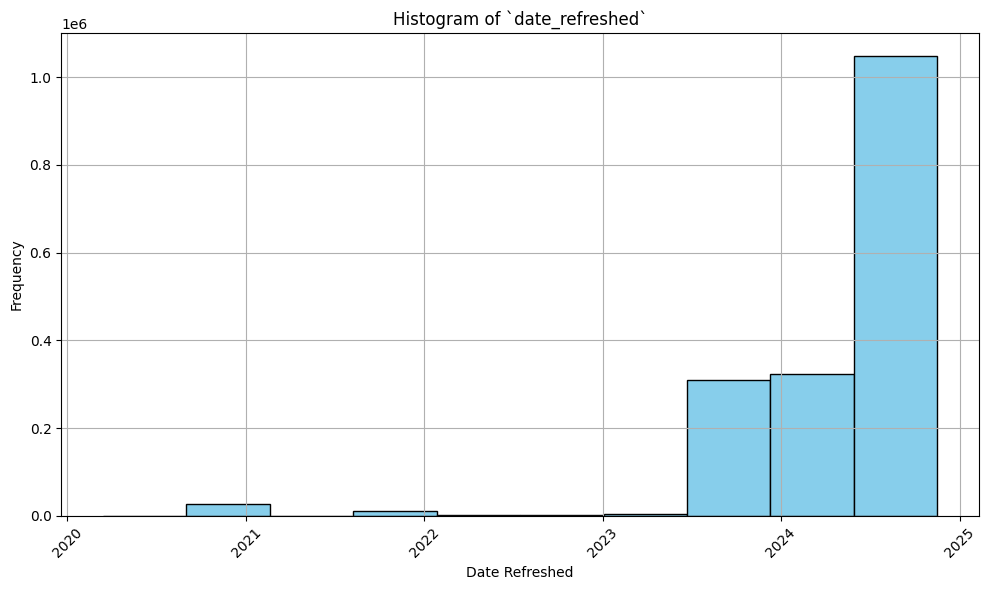

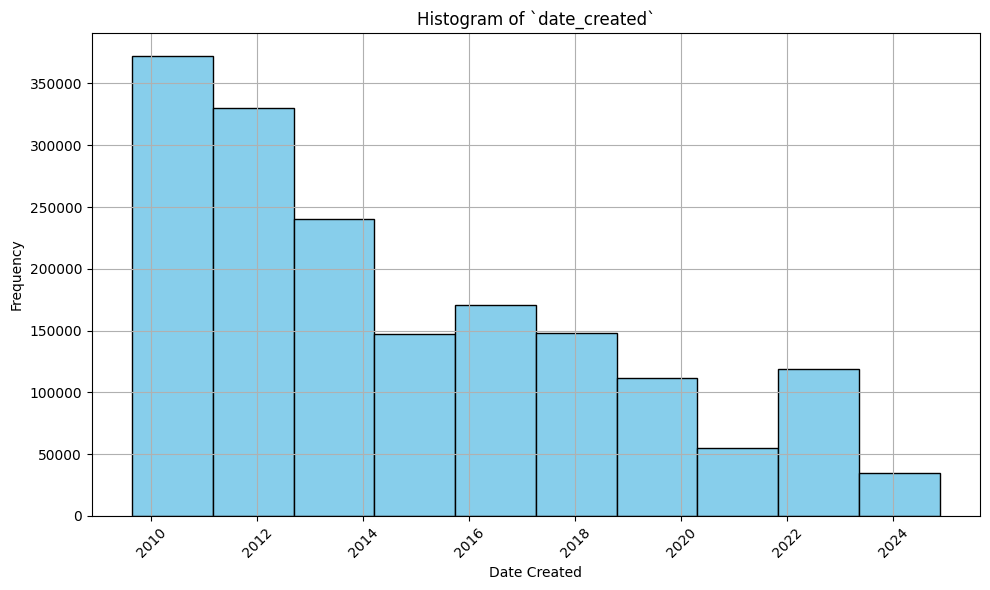

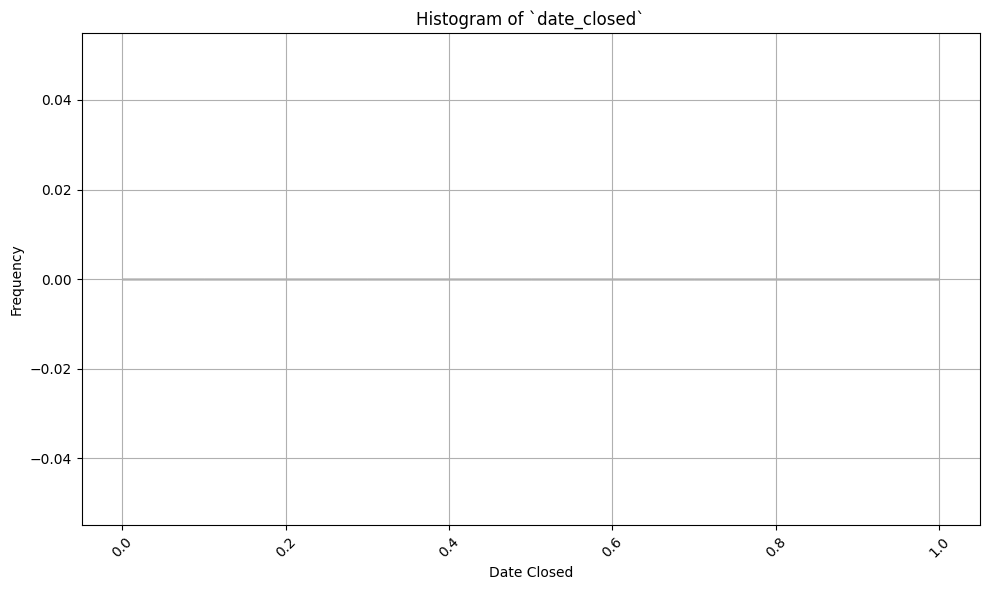

In [123]:
# Plot histogram

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
df['date_refreshed'].hist(bins=10, color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel("Date Refreshed")
plt.ylabel("Frequency")
plt.title("Histogram of `date_refreshed`")
plt.xticks(rotation=45)

# Show plot
plt.tight_layout()
plt.show()

# Plot histogram
plt.figure(figsize=(10, 6))
df['date_created'].hist(bins=10, color='skyblue', edgecolor='black')


# Add labels and title
plt.xlabel("Date Created")
plt.ylabel("Frequency")
plt.title("Histogram of `date_created`")
plt.xticks(rotation=45)

# Show plot
plt.tight_layout()
plt.show()

# Plot histogram
plt.figure(figsize=(10, 6))
df['date_closed'].hist(bins=10, color='skyblue', edgecolor='black')


# Add labels and title
plt.xlabel("Date Closed")
plt.ylabel("Frequency")
plt.title("Histogram of `date_closed`")
plt.xticks(rotation=45)

# Show plot
plt.tight_layout()
plt.show()

""
0
1
2
3
4
...
20600
20601
20602
20603


<Axes: >

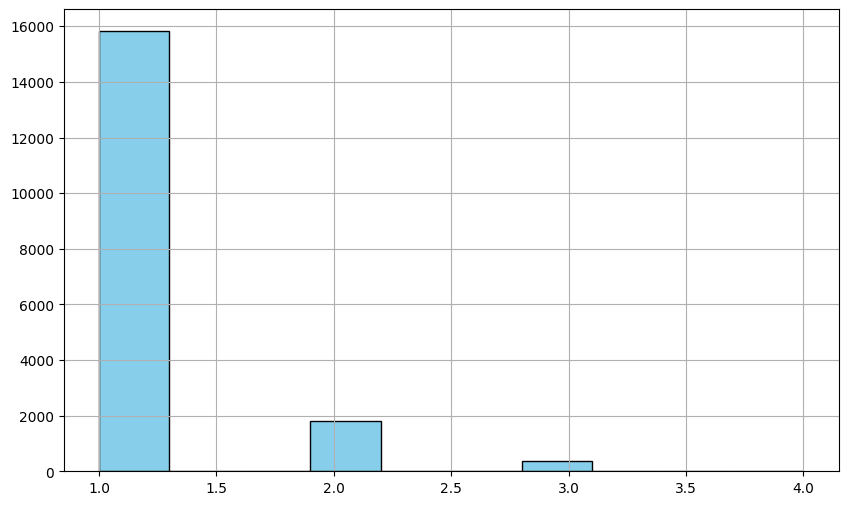

In [47]:
#find how often places have the exact same name and location
df['name_lat_lng'] = df['name'] + df['lat'].astype(str) + df['lng'].astype(str)
vcs = df['name_lat_lng'].value_counts()

#plot histogram of it
plt.figure(figsize=(10, 6))
vcs.hist(bins=10, color='skyblue', edgecolor='black')


In [34]:
land_use_cells = pd.read_parquet("data/input_files/retail_landuse_h3.parquet")
import utils as ut
land_use_cells= ut.to_geoframe(land_use_cells)


In [36]:
land_use_cells

#to geojson 
land_use_cells.to_file("output_land_use_cells.geojson", driver="GeoJSON")

In [16]:
foursquare

,name,lat,lng,address,level1_category_name,level2_category_name,level3_category_name,level4_category_name,h3_11,geometry
0,Bellcraig community centre,55.901058,-4.292746,10 Gorstan St,Community and Government,Community Center,None,None,8b1909ae24b0fff,POINT (256749.697 669924.914)
1,Smart a B C,55.896797,-4.329515,14 Netherton Ave,Business and Professional Services,Automotive Service,Automotive Repair Shop,None,8b1909af149afff,POINT (254435.307 669527.615)
2,DJ's,55.843726,-4.262244,None,Dining and Drinking,Bar,None,None,8b1909ac1b9bfff,POINT (258447.777 663483.011)
3,The Forge Shopping Centre,55.853484,-4.200165,1221 Gallowgate,Retail,Shopping Mall,None,None,8b1909ae8c45fff,POINT (262368.645 664443.38)
4,Desa Ink,55.882145,-4.254049,158 Saracen St,Business and Professional Services,Health and Beauty Service,Tattoo Parlor,None,8b1909ae30b1fff,POINT (259100.095 667740.975)
...,...,...,...,...,...,...,...,...,...,...
2222406,Cut Loose,49.915617,-6.311773,5 Strand,Business and Professional Services,Health and Beauty Service,Hair Salon,None,8b18729050ecfff,POINT (90584.134 10629.299)
2222407,Fay Page,49.965794,-6.302063,None,Retail,Fashion Retail,Jewelry Store,None,8b1872920c8efff,POINT (91602.007 16165.457)
2222408,St Mary's Library,49.913766,-6.313197,None,Community and Government,Library,None,None,8b18729050cbfff,POINT (90470.044 10429.47)
2222409,Scilly Organics,49.960940,-6.281992,None,Retail,Food and Beverage Retail,Grocery Store,Organic Grocery,8b1872920ba0fff,POINT (93009.911 15543.33)
